<a href="https://colab.research.google.com/github/HSE-LAMBDA/MLDM-2022/blob/master/01-intro/DataHandling_HW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Please, fill in before you start:

First Name: Subbotin

Last Name: Semyon

Group: LPI RAS

### After the assigment is done, please, push it to a [private GitHub repository](https://docs.github.com/en/github/administering-a-repository/managing-repository-settings/setting-repository-visibility) and invite [PlaZMaD](https://github.com/plazmad) [as collaborators](https://docs.github.com/en/account-and-profile/setting-up-and-managing-your-github-user-account/managing-access-to-your-personal-repositories/inviting-collaborators-to-a-personal-repository).

Get the Titanic dataset:

In [5]:
#!wget https://raw.githubusercontent.com/HSE-LAMBDA/MLDM-2022/main/01-intro/train.csv

In [6]:
import pandas as pd
import numpy as np
data = pd.read_csv("train.csv", index_col='PassengerId')
data.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


#### About the data
Here's some of the columns
* Name - a string with person's full name
* Survived - 1 if a person survived the shipwreck, 0 otherwise.
* Pclass - passenger class. Pclass == 3 is cheap'n'cheerful, Pclass == 1 is for moneybags.
* Sex - a person's gender
* Age - age in years, if available
* SibSp - number of siblings on a ship
* Parch - number of parents on a ship
* Fare - ticket cost
* Embarked - port where the passenger embarked
 * C = Cherbourg; Q = Queenstown; S = Southampton

## Task 1 (1 point)

In [ ]:
# Compute survival rate for each of the three passenger classes (`Pclass` = 1, 2 and 3)
# (can you do it using groupby?)

Pclass = data['Pclass'].to_numpy()
Survived = data['Survived'].to_numpy()

for i in range(1, 4):
    print( f' % of survival in {i} class is {( (sum(( Pclass == i ) & (Survived) ) / sum( Pclass == i )))*100}')

 % of survival in 1 class is 62.96296296296296
 % of survival in 2 class is 47.28260869565217
 % of survival in 3 class is 24.236252545824847


## Task 2 (1 point)

/tmp/ipykernel_44264/1442463355.py:11: RuntimeWarning: Mean of empty slice
  y = [float(Parch[SibSp == i].mean()) for i in x]
/usr/lib/python3.14/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Text(0, 0.5, 'average number of parents')

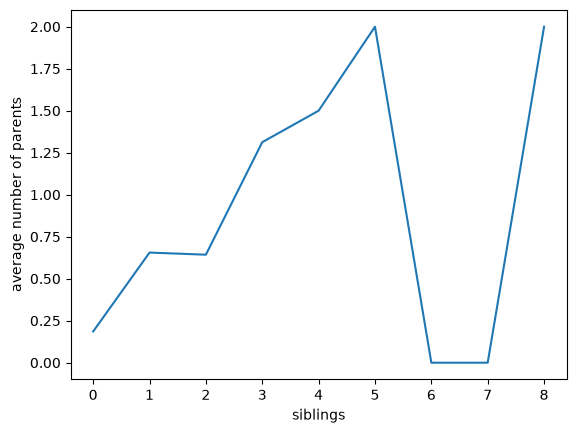

In [ ]:
# Plot the average number of parents onboard (`Parch`) as a function of the 
# number of siblings onboard (`SibSp`)

import matplotlib.pyplot as plt
import math

SibSp = data['SibSp'].to_numpy()
Parch = data['Parch'].to_numpy()

x = list(range(SibSp.max()+1))
y = [float(Parch[SibSp == i].mean()) for i in x]
y = [0 if math.isnan(i) else i for i in y]

plt.plot(x,y)
plt.xlabel('siblings')
plt.ylabel('average number of parents')

In [ ]:
data.columns

Index(['Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket',
       'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [ ]:
lol = data[['Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']].copy()
lol.isna().any()

Survived    False
Pclass      False
Name        False
Sex         False
Age          True
SibSp       False
Parch       False
Ticket      False
Fare        False
Cabin        True
Embarked     True
dtype: bool

## Task 3 (2 points)

In [ ]:
# Build a model with KNeighborsClassifier to get the accuracy of
# at least 0.75 on the validation part of the dataset

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

def feature_selection_and_preprocessing(dataset):
    features = dataset[['Pclass','Sex', 'Age', 'SibSp', "Fare", "Parch"]].copy()

    features['Sex'] = features['Sex'].map({'male': 0, 'female': 100})
    features['Age'] = features['Age'].fillna(features['Age'].median())
    features['Pclass'] *= 30
    #features['SibSp'] *= 20
    #features['Parch'] *= 50

    features["Fare"] /= features["Fare"].mean()
    features["Fare"] *= 100
    return features

model = KNeighborsClassifier(
    weights= 'distance',
    n_neighbors=7
)


# Validation code (do not touch)
data = pd.read_csv("train.csv", index_col='PassengerId')
data_train = data.iloc[:-100]
data_test = data.iloc[-100:]

model.fit(
    feature_selection_and_preprocessing(
        data_train.drop('Survived', axis=1)
    ),
    data_train['Survived']
)

test_predictions = model.predict(
    feature_selection_and_preprocessing(
        data_test.drop('Survived', axis=1)
    )
)
print("Test accuracy:", accuracy_score(
    data_test['Survived'],
    test_predictions
))

Test accuracy: 0.83


## Task 4 (2 points)

Check how your model from the previous task performs on randomized splits to train / test (with test set of size 100). Plot the histogram of the test error distribution.

*Hint: check sklearn's `sklearn.model_selection.train_test_split` function.*

mean = 0.20
sigma = 0.04


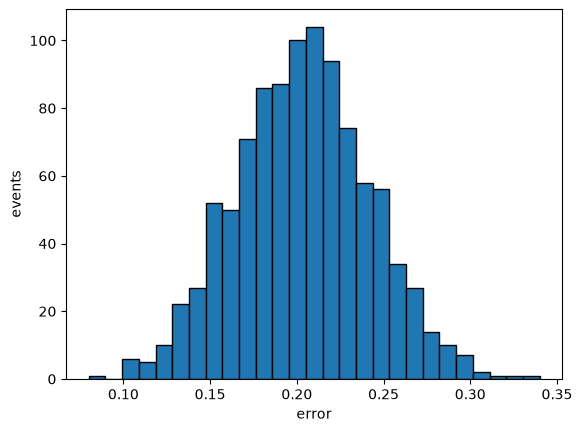

In [ ]:
from sklearn.model_selection import train_test_split

errors = []
for i in range (1000):
    data_train, data_test, y_train, y_test = train_test_split(
        data, data['Survived'],
        test_size=100
    )

    model.fit(
        feature_selection_and_preprocessing(
            data_train.drop('Survived', axis=1)
        ),
        y_train
    )

    test_predictions = model.predict(
        feature_selection_and_preprocessing(
            data_test.drop('Survived', axis=1)
        )
    )
    errors.append(round (1-accuracy_score(
        y_test,
        test_predictions
    ), 2))


nbins = int( (max(errors) - min(errors))*100 + 1)

plt.hist(errors, bins=nbins, edgecolor='black')
plt.xlabel('error')
plt.ylabel('events')

print(f'mean = {np.mean(errors):.2f}')
print(f'sigma = {np.std(errors):.2f}')

### Ну я добился результата (80 +/- 4)%
Лучше не получилось, к масштабированию и n_neighbors результат слабо чувствителен